# Phase A — Dataset Preprocessing and Analysis

This notebook is used to understand the GRaM transient airfoil dataset before training.

This notebook includes:

1. **Dataset structure and split sanity checks**
2. **Interactive 3D geometry preview** centered on the airfoil region
3. **Separate velocity and pressure contour cells** focused near the airfoils
4. **Animated temporal flow plots** across the 10-frame window
5. **Cross-sample comparison panels** for multiple geometries
6. **Additional diagnostics** such as airfoil coverage, boundary distance, and speed distributions

The goal is to build intuition about geometry, flow scale, local wake behavior, and variability across samples.

In [26]:
from pathlib import Path
import importlib
import sys

from IPython.display import HTML
from matplotlib import animation
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation
import numpy as np
import pandas as pd
import yaml

try:
    import plotly.graph_objects as go
    import plotly.io as pio
    pio.renderers.default = "plotly_mimetype+notebook_connected"
    PLOTLY_AVAILABLE = True
except Exception:
    go = None
    PLOTLY_AVAILABLE = False

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import src.datasets.gram_dataset as gram_dataset_module
import src.datasets.preprocessing as preprocessing_module
import src.datasets.splits as splits_module

importlib.reload(gram_dataset_module)
importlib.reload(preprocessing_module)
importlib.reload(splits_module)

GRAMDataset = gram_dataset_module.GRAMDataset
scan_dataset_files = gram_dataset_module.scan_dataset_files
PhaseAPreprocessor = preprocessing_module.PhaseAPreprocessor
fit_velocity_stats = preprocessing_module.fit_velocity_stats
build_geometry_split = splits_module.build_geometry_split
summarize_split = splits_module.summarize_split

plt.style.use("seaborn-v0_8")
pd.set_option("display.max_columns", 30)


def temporal_speed(velocity: np.ndarray) -> np.ndarray:
    return np.linalg.norm(velocity, axis=-1)


def compute_focus_bounds(
    pos: np.ndarray,
    airfoil_mask: np.ndarray,
    pad_ratio: float = 0.35,
    min_pad: float = 0.02,
):
    """Build an expanded bounding box around the airfoil region."""
    pos = np.asarray(pos, dtype=np.float32)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)
    airfoil_points = pos[airfoil_mask]

    if airfoil_points.size == 0:
        lo = pos.min(axis=0)
        hi = pos.max(axis=0)
    else:
        lo = airfoil_points.min(axis=0)
        hi = airfoil_points.max(axis=0)

    span = np.maximum(hi - lo, min_pad)
    pad = span * pad_ratio + min_pad
    return lo - pad, hi + pad


def sample_random_indices(indices: np.ndarray, max_points: int, seed: int = 0) -> np.ndarray:
    indices = np.asarray(indices, dtype=np.int64)
    if indices.size <= max_points:
        return np.sort(indices)
    rng = np.random.default_rng(seed)
    chosen = rng.choice(indices, size=max_points, replace=False)
    return np.sort(chosen.astype(np.int64))


def select_airfoil_slice(
    pos: np.ndarray,
    values: np.ndarray,
    airfoil_mask: np.ndarray,
    axis: int = 2,
    margin_ratio: float = 0.35,
    width_scale: float = 1.5,
    max_points: int = 12000,
    seed: int = 0,
):
    """Select a 2D slice focused on the airfoil neighborhood for contour-style plots."""
    pos = np.asarray(pos, dtype=np.float32)
    values = np.asarray(values)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)

    if axis == 0:
        axes_2d = (1, 2)
        labels = ("y", "z")
    elif axis == 1:
        axes_2d = (0, 2)
        labels = ("x", "z")
    else:
        axes_2d = (0, 1)
        labels = ("x", "y")

    focus_lo, focus_hi = compute_focus_bounds(pos, airfoil_mask, pad_ratio=margin_ratio)
    in_box = (
        (pos[:, axes_2d[0]] >= focus_lo[axes_2d[0]])
        & (pos[:, axes_2d[0]] <= focus_hi[axes_2d[0]])
        & (pos[:, axes_2d[1]] >= focus_lo[axes_2d[1]])
        & (pos[:, axes_2d[1]] <= focus_hi[axes_2d[1]])
    )

    reference = pos[airfoil_mask, axis] if airfoil_mask.any() else pos[:, axis]
    center = float(np.median(reference))
    ref_span = float(np.ptp(reference)) if reference.size else float(np.ptp(pos[:, axis]))
    width = max(ref_span * width_scale + 0.01, 0.03)

    slice_mask = in_box & (np.abs(pos[:, axis] - center) <= width)
    if slice_mask.sum() < 300:
        width = max(width * 1.75, 0.05)
        slice_mask = in_box & (np.abs(pos[:, axis] - center) <= width)
    if slice_mask.sum() < 300:
        slice_mask = in_box

    idx = sample_random_indices(np.flatnonzero(slice_mask), max_points=max_points, seed=seed)
    coords_2d = pos[idx][:, axes_2d]
    return idx, coords_2d, values[idx], center, width, labels, airfoil_mask[idx]


def plot_scalar_contour(
    ax,
    pos,
    scalar,
    airfoil_mask,
    title,
    cmap="viridis",
    axis=2,
    levels=30,
    seed=0,
):
    idx, coords_2d, vals, center, width, labels, airfoil_slice = select_airfoil_slice(
        pos,
        scalar,
        airfoil_mask,
        axis=axis,
        seed=seed,
    )
    x, y = coords_2d[:, 0], coords_2d[:, 1]
    try:
        tri = Triangulation(x, y)
        artist = ax.tricontourf(tri, vals, levels=levels, cmap=cmap)
    except Exception:
        artist = ax.scatter(x, y, c=vals, s=6, cmap=cmap)

    if airfoil_slice.any():
        ax.scatter(x[airfoil_slice], y[airfoil_slice], s=10, c="black", alpha=0.75, label="airfoil")
        ax.legend(loc="upper right")

    plt.colorbar(artist, ax=ax, shrink=0.85)
    ax.set_title(f"{title}\nfocused near airfoil | slice axis={axis}, center={center:.3f}, width={width:.3f}")
    ax.set_xlabel(labels[0])
    ax.set_ylabel(labels[1])
    ax.set_aspect("equal")
    return idx


def plot_velocity_quiver(ax, pos, velocity, airfoil_mask, title, axis=2, seed=0):
    idx, coords_2d, _, center, width, labels, airfoil_slice = select_airfoil_slice(
        pos,
        temporal_speed(velocity),
        airfoil_mask,
        axis=axis,
        max_points=1800,
        seed=seed,
    )
    x, y = coords_2d[:, 0], coords_2d[:, 1]

    if axis == 0:
        vel_2d = velocity[idx][:, [1, 2]]
    elif axis == 1:
        vel_2d = velocity[idx][:, [0, 2]]
    else:
        vel_2d = velocity[idx][:, [0, 1]]

    speed = np.linalg.norm(vel_2d, axis=1)
    artist = ax.quiver(
        x,
        y,
        vel_2d[:, 0],
        vel_2d[:, 1],
        speed,
        cmap="plasma",
        angles="xy",
        scale_units="xy",
        scale=None,
        width=0.002,
    )
    if airfoil_slice.any():
        ax.scatter(x[airfoil_slice], y[airfoil_slice], s=10, c="black", alpha=0.75)
    plt.colorbar(artist, ax=ax, shrink=0.85, label="projected speed")
    ax.set_title(f"{title}\nfocused near airfoil | slice axis={axis}, center={center:.3f}, width={width:.3f}")
    ax.set_xlabel(labels[0])
    ax.set_ylabel(labels[1])
    ax.set_aspect("equal")


def make_interactive_geometry_figure(
    pos: np.ndarray,
    airfoil_mask: np.ndarray,
    title: str = "Interactive 3D geometry around airfoils",
    max_fluid_points: int = 15000,
    seed: int = 0,
):
    """Create an interactive 3D geometry preview focused on the airfoil region."""
    if not PLOTLY_AVAILABLE:
        raise ImportError("Plotly is required for the interactive 3D preview.")

    pos = np.asarray(pos, dtype=np.float32)
    airfoil_mask = np.asarray(airfoil_mask, dtype=bool)
    focus_lo, focus_hi = compute_focus_bounds(pos, airfoil_mask, pad_ratio=0.5)

    in_focus = np.all((pos >= focus_lo) & (pos <= focus_hi), axis=1)
    fluid_idx = sample_random_indices(np.flatnonzero(in_focus & ~airfoil_mask), max_fluid_points, seed=seed)
    airfoil_idx = sample_random_indices(np.flatnonzero(airfoil_mask), max_points=6000, seed=seed)

    fig = go.Figure()
    fig.add_trace(
        go.Scatter3d(
            x=pos[fluid_idx, 0],
            y=pos[fluid_idx, 1],
            z=pos[fluid_idx, 2],
            mode="markers",
            name="fluid",
            marker=dict(size=2, color="rgba(70,130,180,0.28)"),
        )
    )
    fig.add_trace(
        go.Scatter3d(
            x=pos[airfoil_idx, 0],
            y=pos[airfoil_idx, 1],
            z=pos[airfoil_idx, 2],
            mode="markers",
            name="airfoil",
            marker=dict(size=3, color="crimson"),
        )
    )
    fig.update_layout(
        title=title,
        height=650,
        scene=dict(
            xaxis=dict(title="x", range=[float(focus_lo[0]), float(focus_hi[0])]),
            yaxis=dict(title="y", range=[float(focus_lo[1]), float(focus_hi[1])]),
            zaxis=dict(title="z", range=[float(focus_lo[2]), float(focus_hi[2])]),
            aspectmode="data",
        ),
        margin=dict(l=0, r=0, t=50, b=0),
    )
    return fig


def make_temporal_flow_animation(sample: dict, axis: int = 2, interval: int = 800):
    """Animate velocity and pressure evolution around the airfoils over the full 10-frame window."""
    pos = sample["pos"]
    airfoil_mask = sample["airfoil_mask"]
    pressure = sample.get("pressure")
    speed_frames = np.concatenate(
        [temporal_speed(sample["velocity_in"]), temporal_speed(sample["velocity_out"])],
        axis=0,
    )
    labels = [f"t{step}" for step in range(-4, 6)]

    if pressure is None:
        fig, ax = plt.subplots(figsize=(6, 5))
        axes = [ax]
    else:
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        axes = list(np.ravel(axes))

    def update(frame_idx: int):
        for ax in axes:
            ax.clear()

        plot_scalar_contour(
            axes[0],
            pos,
            speed_frames[frame_idx],
            airfoil_mask,
            title=f"Velocity magnitude — {labels[frame_idx]}",
            cmap="viridis",
            axis=axis,
            seed=frame_idx,
        )

        if pressure is not None:
            plot_scalar_contour(
                axes[1],
                pos,
                pressure[frame_idx],
                airfoil_mask,
                title=f"Pressure — {labels[frame_idx]}",
                cmap="coolwarm",
                axis=axis,
                seed=frame_idx,
            )
        fig.suptitle("Temporal flow evolution near the airfoil", fontsize=14)
        return axes

    anim = animation.FuncAnimation(fig, update, frames=len(speed_frames), interval=interval, repeat=True)
    plt.close(fig)
    return HTML(anim.to_jshtml())


def pick_distinct_records(records, max_samples: int = 3):
    chosen = []
    seen = set()
    for record in records:
        if record.simulation_id in seen:
            continue
        seen.add(record.simulation_id)
        chosen.append(record)
        if len(chosen) >= max_samples:
            break
    return chosen


def build_summary_frame(dataset, limit=40):
    rows = []
    for idx in range(min(limit, len(dataset))):
        sample = dataset[idx]
        vel_in_speed = temporal_speed(sample["velocity_in"])
        vel_out_speed = temporal_speed(sample["velocity_out"])
        pressure = sample.get("pressure")
        rows.append(
            {
                "file_name": sample["metadata"]["file_name"],
                "simulation_id": sample["metadata"]["simulation_id"],
                "window_id": sample["metadata"]["window_id"],
                "variant_id": sample["metadata"]["variant_id"],
                "num_points": sample["metadata"]["num_points"],
                "airfoil_fraction": sample["metadata"]["num_airfoil_points"] / sample["metadata"]["num_points"],
                "speed_in_mean": float(vel_in_speed.mean()),
                "speed_out_mean": float(vel_out_speed.mean()),
                "speed_in_max": float(vel_in_speed.max()),
                "pressure_mean": float(np.mean(pressure)) if pressure is not None else np.nan,
                "pressure_std": float(np.std(pressure)) if pressure is not None else np.nan,
            }
        )
    return pd.DataFrame(rows)

In [27]:
config = yaml.safe_load((ROOT / "configs" / "phase_a.yaml").read_text())
records = scan_dataset_files(ROOT / config["data"]["root"])
split = build_geometry_split(
    records,
    val_fraction=config["split"]["val_fraction"],
    seed=config["split"]["seed"],
    num_test_simulations=int(config["split"].get("num_test_simulations", 0)),
    test_simulation_ids=config["split"].get("test_simulation_ids"),
)
print(summarize_split(split))

train_dataset = GRAMDataset(
    ROOT / config["data"]["root"],
    records=split["train_records"],
    include_pressure=config["data"].get("include_pressure", True),
)
val_dataset = GRAMDataset(
    ROOT / config["data"]["root"],
    records=split["val_records"],
    include_pressure=config["data"].get("include_pressure", True),
)
test_dataset = GRAMDataset(
    ROOT / config["data"]["root"],
    records=split["test_records"],
    include_pressure=config["data"].get("include_pressure", True),
)

velocity_stats = fit_velocity_stats(train_dataset, max_samples=20)
preprocessor = PhaseAPreprocessor(
    coordinate_mode=config["preprocessing"]["coordinate_mode"],
    velocity_mean=velocity_stats["mean"],
    velocity_std=velocity_stats["std"],
    subsample_points=config["preprocessing"]["subsample_points"],
    seed=config["split"]["seed"],
)

raw_train_sample = train_dataset[0]
processed_train_sample = preprocessor(raw_train_sample)
raw_val_sample = val_dataset[0] if len(val_dataset) else None
raw_test_sample = test_dataset[0] if len(test_dataset) else None

record_df = pd.DataFrame(
    [
        {
            "simulation_id": record.simulation_id,
            "window_id": record.window_id,
            "variant_id": record.variant_id,
        }
        for record in records
    ]
)
summary_df = build_summary_frame(train_dataset, limit=40)

print(
    f"Train records: {len(train_dataset)} | Validation records: {len(val_dataset)} | "
    f"Test records: {len(test_dataset)}"
)
print(f"Held-out test simulation IDs: {split['test_simulation_ids']}")
print(f"Processed feature shape: {processed_train_sample['input_features'].shape}")
summary_df.head()

{'seed': 42, 'val_fraction': 0.2, 'num_train_records': 545, 'num_val_records': 160, 'num_test_records': 105, 'num_train_simulations': 16, 'num_val_simulations': 4, 'num_test_simulations': 2, 'overlap_simulation_ids': [], 'overlap_train_val': [], 'overlap_train_test': [], 'overlap_val_test': []}
Train records: 545 | Validation records: 160 | Test records: 105
Held-out test simulation IDs: [1026, 3006]
Processed feature shape: (4096, 20)


,file_name,simulation_id,window_id,variant_id,num_points,airfoil_fraction,speed_in_mean,speed_out_mean,speed_in_max,pressure_mean,pressure_std
0,1021_1-0.npz,1021,1,0,100000,0.2,35.057236,35.104885,84.590569,-143.401703,413.480286
1,1021_1-1.npz,1021,1,1,100000,0.2,34.924183,34.962067,83.003113,-143.831345,413.036438
2,1021_1-2.npz,1021,1,2,100000,0.2,35.063683,35.070019,82.795120,-143.300797,414.466553
3,1021_1-3.npz,1021,1,3,100000,0.2,35.108566,35.024540,80.866577,-143.965729,413.551788
4,1021_1-4.npz,1021,1,4,100000,0.2,34.916920,35.010735,81.280067,-144.196487,412.332855


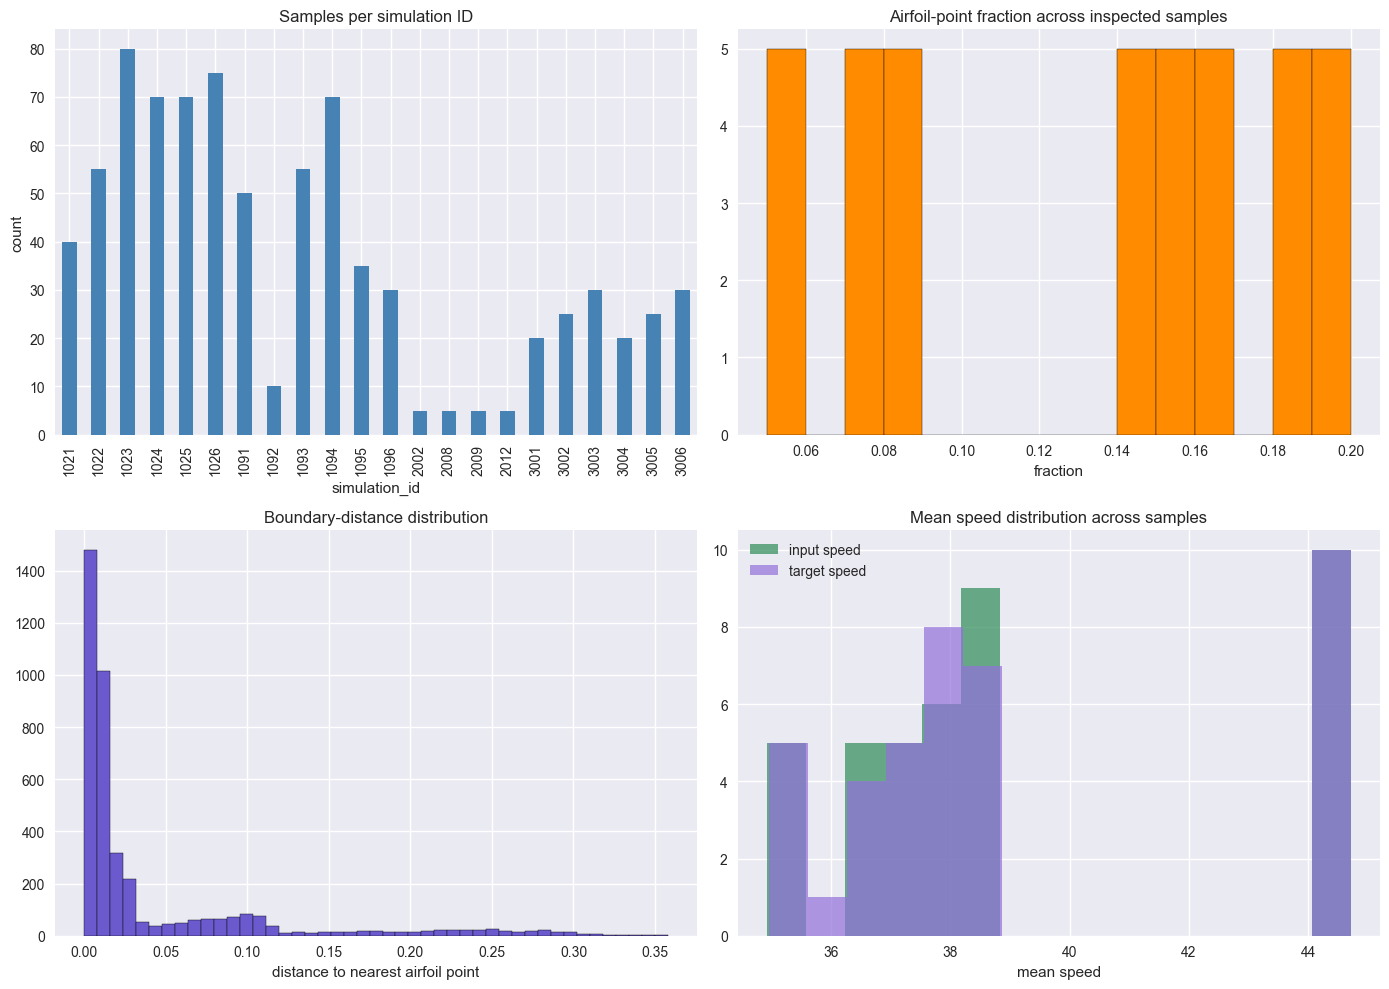

,airfoil_fraction,speed_in_mean,pressure_std
simulation_id,,,
1021,0.13241,39.036845,388.085238


In [19]:
pressure = raw_train_sample.get("pressure")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
record_df.groupby("simulation_id").size().plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Samples per simulation ID")
axes[0, 0].set_xlabel("simulation_id")
axes[0, 0].set_ylabel("count")

axes[0, 1].hist(summary_df["airfoil_fraction"], bins=15, color="darkorange", edgecolor="black")
axes[0, 1].set_title("Airfoil-point fraction across inspected samples")
axes[0, 1].set_xlabel("fraction")

axes[1, 0].hist(processed_train_sample["boundary_distance"], bins=45, color="slateblue", edgecolor="black")
axes[1, 0].set_title("Boundary-distance distribution")
axes[1, 0].set_xlabel("distance to nearest airfoil point")

axes[1, 1].hist(summary_df["speed_in_mean"], bins=15, alpha=0.7, label="input speed", color="seagreen")
axes[1, 1].hist(summary_df["speed_out_mean"], bins=15, alpha=0.7, label="target speed", color="mediumpurple")
axes[1, 1].set_title("Mean speed distribution across samples")
axes[1, 1].set_xlabel("mean speed")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

summary_df.groupby("simulation_id")[["airfoil_fraction", "speed_in_mean", "pressure_std"]].mean().head(10)

## Interactive 3D geometry preview

This cell focuses the 3D view around the airfoil region so the local geometry is easier to inspect.

In [20]:
make_interactive_geometry_figure(
    raw_train_sample["pos"],
    raw_train_sample["airfoil_mask"],
    title=f"Interactive 3D geometry around airfoils — simulation {raw_train_sample['metadata']['simulation_id']}",
)

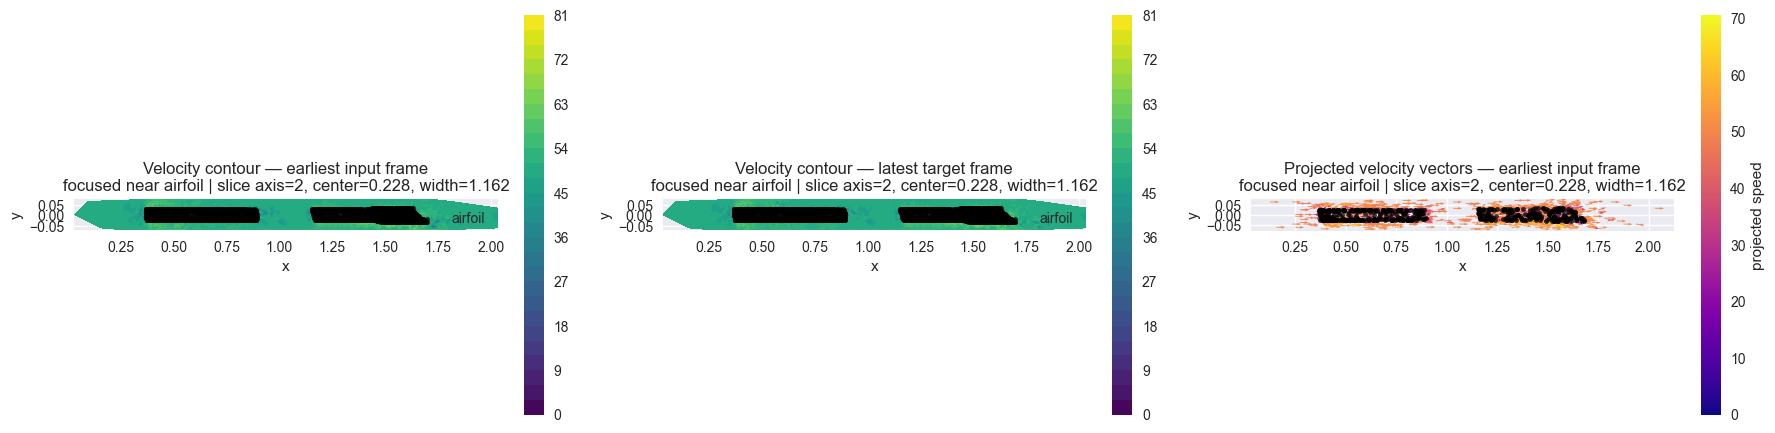

,metric,value
0,input_mean_speed,35.057236
1,target_mean_speed,35.104885
2,input_max_speed,84.590569
3,target_max_speed,85.178261


In [21]:
speed_in = temporal_speed(raw_train_sample["velocity_in"])
speed_out = temporal_speed(raw_train_sample["velocity_out"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_scalar_contour(
    axes[0],
    raw_train_sample["pos"],
    speed_in[0],
    raw_train_sample["airfoil_mask"],
    title="Velocity contour — earliest input frame",
    cmap="viridis",
    axis=2,
)
plot_scalar_contour(
    axes[1],
    raw_train_sample["pos"],
    speed_out[-1],
    raw_train_sample["airfoil_mask"],
    title="Velocity contour — latest target frame",
    cmap="viridis",
    axis=2,
)
plot_velocity_quiver(
    axes[2],
    raw_train_sample["pos"],
    raw_train_sample["velocity_in"][0],
    raw_train_sample["airfoil_mask"],
    title="Projected velocity vectors — earliest input frame",
    axis=2,
)

plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "metric": ["input_mean_speed", "target_mean_speed", "input_max_speed", "target_max_speed"],
        "value": [
            float(speed_in.mean()),
            float(speed_out.mean()),
            float(speed_in.max()),
            float(speed_out.max()),
        ],
    }
)

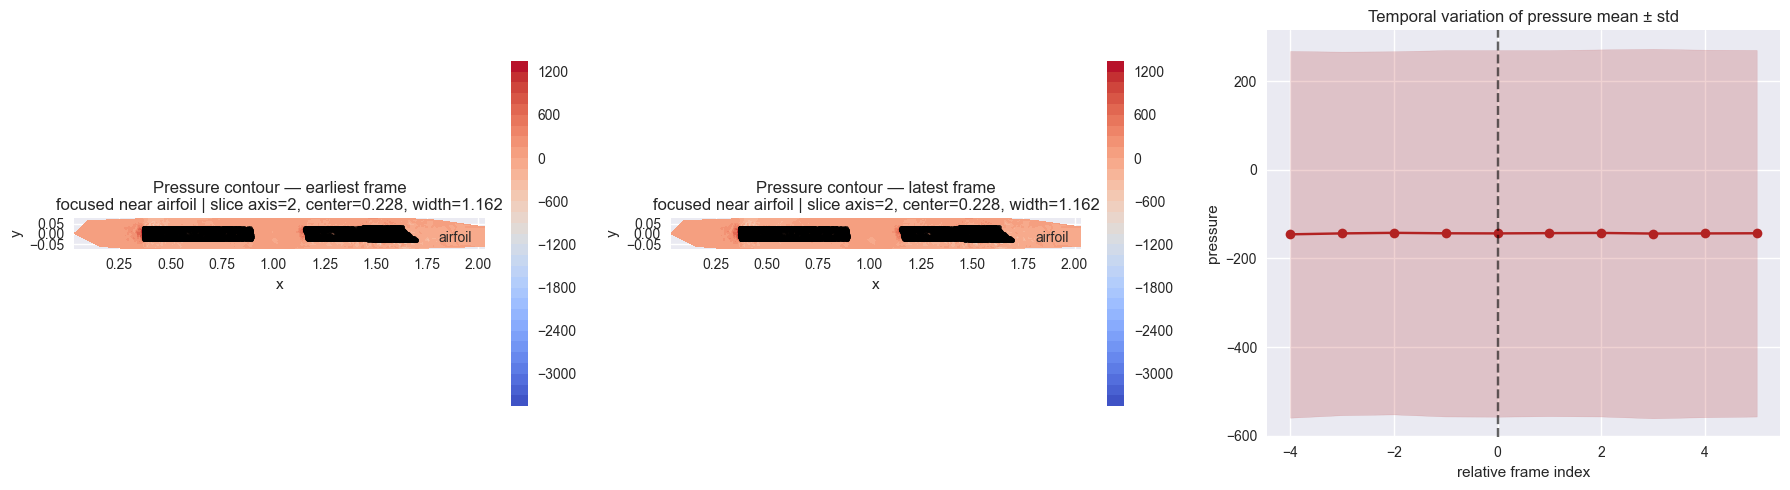

In [22]:
pressure = raw_train_sample.get("pressure")
frame_axis_pressure = np.arange(-4, 6)

if pressure is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    plot_scalar_contour(
        axes[0],
        raw_train_sample["pos"],
        pressure[0],
        raw_train_sample["airfoil_mask"],
        title="Pressure contour — earliest frame",
        cmap="coolwarm",
        axis=2,
    )
    plot_scalar_contour(
        axes[1],
        raw_train_sample["pos"],
        pressure[-1],
        raw_train_sample["airfoil_mask"],
        title="Pressure contour — latest frame",
        cmap="coolwarm",
        axis=2,
    )

    pressure_mean = pressure.mean(axis=1)
    pressure_std = pressure.std(axis=1)
    axes[2].plot(frame_axis_pressure, pressure_mean, marker="o", color="firebrick")
    axes[2].fill_between(
        frame_axis_pressure,
        pressure_mean - pressure_std,
        pressure_mean + pressure_std,
        color="firebrick",
        alpha=0.2,
    )
    axes[2].axvline(0, color="black", linestyle="--", alpha=0.6)
    axes[2].set_title("Temporal variation of pressure mean ± std")
    axes[2].set_xlabel("relative frame index")
    axes[2].set_ylabel("pressure")
    plt.tight_layout()
    plt.show()

    pd.DataFrame(
        {
            "metric": ["pressure_mean", "pressure_std", "pressure_min", "pressure_max"],
            "value": [
                float(pressure.mean()),
                float(pressure.std()),
                float(pressure.min()),
                float(pressure.max()),
            ],
        }
    )
else:
    print("Pressure is not available for this sample.")

## Animated temporal flow plots

Use the animation below to inspect how velocity magnitude and pressure evolve around the airfoils across the full 10-frame window.

In [23]:
make_temporal_flow_animation(raw_train_sample, axis=2, interval=700)

/var/folders/bn/sthfgkwn49b8d7flylj82kch0000gn/T/ipykernel_17549/822011085.py:148: UserWarning: Adding colorbar to a different Figure <Figure size 1300x500 with 3 Axes> than <Figure size 800x550 with 0 Axes> which fig.colorbar is called on.
  plt.colorbar(artist, ax=ax, shrink=0.85)
/var/folders/bn/sthfgkwn49b8d7flylj82kch0000gn/T/ipykernel_17549/822011085.py:148: UserWarning: Adding colorbar to a different Figure <Figure size 1300x500 with 4 Axes> than <Figure size 800x550 with 0 Axes> which fig.colorbar is called on.
  plt.colorbar(artist, ax=ax, shrink=0.85)
/var/folders/bn/sthfgkwn49b8d7flylj82kch0000gn/T/ipykernel_17549/822011085.py:148: UserWarning: Adding colorbar to a different Figure <Figure size 1300x500 with 5 Axes> than <Figure size 800x550 with 0 Axes> which fig.colorbar is called on.
  plt.colorbar(artist, ax=ax, shrink=0.85)
/var/folders/bn/sthfgkwn49b8d7flylj82kch0000gn/T/ipykernel_17549/822011085.py:148: UserWarning: Adding colorbar to a different Figure <Figure size 1

<Figure size 800x550 with 0 Axes>

## Cross-sample comparison panels

This section compares multiple geometries side by side so differences in local flow structure are easier to spot.

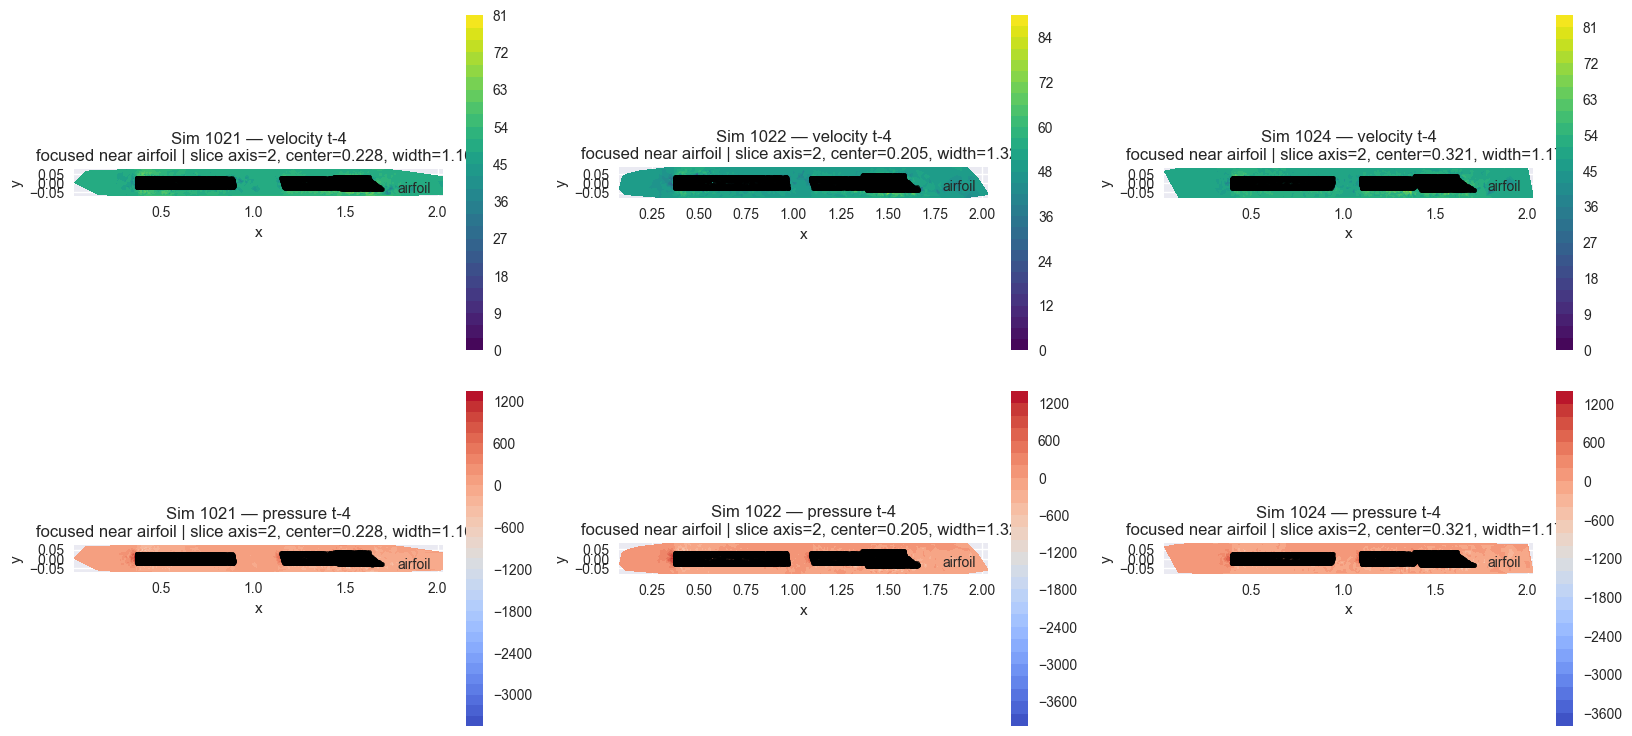

,simulation_id,file_name,airfoil_fraction,mean_input_speed,pressure_std
0,1021,1021_1-0.npz,0.20000,35.057236,413.480286
1,1022,1022_1-0.npz,0.23281,33.385860,468.083984
2,1024,1024_1-0.npz,0.21383,35.836468,437.343475


In [24]:
comparison_records = pick_distinct_records(split["train_records"], max_samples=3)
comparison_dataset = GRAMDataset(
    ROOT / config["data"]["root"],
    records=comparison_records,
    include_pressure=config["data"].get("include_pressure", True),
)
comparison_samples = [comparison_dataset[i] for i in range(len(comparison_dataset))]

fig, axes = plt.subplots(2, len(comparison_samples), figsize=(5.5 * len(comparison_samples), 8), squeeze=False)
rows = []
for col, sample in enumerate(comparison_samples):
    sim_id = sample["metadata"]["simulation_id"]
    speed = temporal_speed(sample["velocity_in"])
    plot_scalar_contour(
        axes[0, col],
        sample["pos"],
        speed[0],
        sample["airfoil_mask"],
        title=f"Sim {sim_id} — velocity t-4",
        cmap="viridis",
        axis=2,
        seed=col,
    )

    pressure = sample.get("pressure")
    if pressure is not None:
        plot_scalar_contour(
            axes[1, col],
            sample["pos"],
            pressure[0],
            sample["airfoil_mask"],
            title=f"Sim {sim_id} — pressure t-4",
            cmap="coolwarm",
            axis=2,
            seed=col,
        )
    else:
        axes[1, col].text(0.5, 0.5, "Pressure unavailable", ha="center", va="center")
        axes[1, col].set_axis_off()

    rows.append(
        {
            "simulation_id": sim_id,
            "file_name": sample["metadata"]["file_name"],
            "airfoil_fraction": sample["metadata"]["num_airfoil_points"] / sample["metadata"]["num_points"],
            "mean_input_speed": float(speed.mean()),
            "pressure_std": float(np.std(pressure)) if pressure is not None else np.nan,
        }
    )

plt.tight_layout()
plt.show()

pd.DataFrame(rows)